## Exercício — Simulação da distribuição normal

Considere a densidade da normal padrão,

$$
f(x)=\frac{1}{\sqrt{2\pi}}e^{-x^2/2},
$$

e, para $x>0$, utilize como distribuição proposta uma exponencial com taxa $1$,

$$
g(x)=e^{-x}, \qquad x\geq 0.
$$

1. Para aplicar o método de rejeição-aceitação, determine a constante

$$
c=\sup_{x>0}\frac{f(x)}{g(x)}.
$$

Para isso, encontre o ponto de máximo da razão $f(x)/g(x)$ e obtenha a expressão da probabilidade de aceitação

$$
\frac{f(x)}{c\,g(x)}.
$$

2. A partir do resultado anterior, implemente em Python um algoritmo de rejeição-aceitação para gerar uma amostra de tamanho $n$ da distribuição de $|N(0,1)|$.

3. Utilize sinais aleatórios independentes, com probabilidades iguais de serem positivos ou negativos, para transformar essa amostra em uma amostra de

$$
N(0,1).
$$

Gere também uma amostra de mesmo tamanho utilizando `numpy.random.normal` e compare as duas distribuições por meio de histogramas.

4. Suponha agora que você saiba gerar $Z\sim N(0,1)$. Como você pode utilizar $Z$ para gerar

$$
X\sim N(\mu,\sigma^2)?
$$

Implemente essa transformação para gerar uma amostra de tamanho $n$ de $N(\mu,\sigma^2)$.

5. Gere também uma amostra de $N(\mu,\sigma^2)$ utilizando `numpy.random.normal` e compare os histogramas das duas amostras.

6. Durante a simulação, registre o número total de propostas geradas e calcule a taxa empírica de aceitação,

$$
\widehat{p}_{\text{aceitação}}
=
\frac{\text{número de valores aceitos}}
{\text{número total de propostas}}.
$$

Compare esse valor com a taxa teórica de aceitação do método,

$$
p_{\text{aceitação}}=\frac{1}{c},
$$

onde $c$ é a constante obtida anteriormente. Os valores observado e esperado são compatíveis?

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#Densidade da exponencial
def g(x):
  y = np.exp(-x)
  return y

In [3]:
#Densidade da normal
def f(x):
  return 2*np.exp((-x**2)/2)/np.sqrt(2*np.pi)

In [4]:
c = f(1)/g(1)
c

np.float64(1.315489246958914)

In [5]:
c2 = np.sqrt(2*np.e/np.pi)
c2

np.float64(1.315489246958914)

2. A partir do resultado anterior, implemente em Python um algoritmo de rejeição-aceitação para gerar uma amostra de tamanho $n$ da distribuição de $|N(0,1)|$.

3. Utilize sinais aleatórios independentes, com probabilidades iguais de serem positivos ou negativos, para transformar essa amostra em uma amostra de

$$
N(0,1).
$$

Gere também uma amostra de mesmo tamanho utilizando `numpy.random.normal` e compare as duas distribuições por meio de histogramas.

6. Durante a simulação, registre o número total de propostas geradas e calcule a taxa empírica de aceitação,

$$
\widehat{p}_{\text{aceitação}}
=
\frac{\text{número de valores aceitos}}
{\text{número total de propostas}}.
$$

Compare esse valor com a taxa teórica de aceitação do método,

$$
p_{\text{aceitação}}=\frac{1}{c},
$$

onde $c$ é a constante obtida anteriormente. Os valores observado e esperado são compatíveis?

1.315489246958914
0.7601734505331403
0.7583916030881707
31858
100000


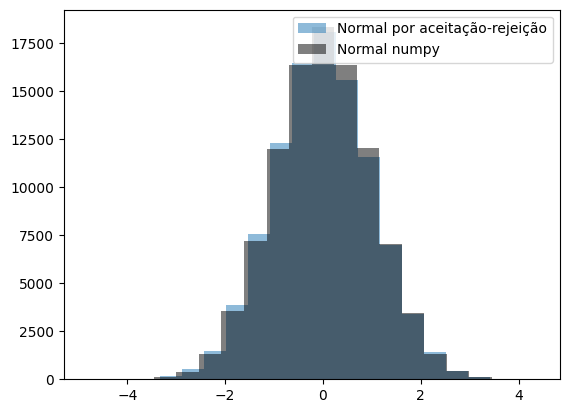

In [10]:
c = np.sqrt(2*np.e/np.pi)
n = 100000
tentativas = 0
sucessos = 0
amostra = []
for i in range(n):
  u = np.random.uniform()
  y = -np.log(u)
  U = np.random.uniform()

  while U*c*g(y) > f(y):
    u = np.random.uniform()
    y = -np.log(u)
    U = np.random.uniform()
    tentativas += 1
  sucessos += 1
  moeda = np.random.uniform()
  if moeda > 0.5:
    amostra.append(y)
  else:
    amostra.append(-y)

print(c)
plt.hist(amostra, bins =20, alpha=.5, label = 'Normal por aceitação-rejeição')
plt.hist(np.random.normal(0,1,n), bins=20, alpha=.5, label='Normal numpy', color='black')
plt.legend()
#probabilidade de aceitação
prob = 1/c
print(prob)
prob_amostral = sucessos/(tentativas+sucessos)
print(prob_amostral)


Ficaram muito proximos os valores das probabilidades

4. Suponha agora que você saiba gerar $Z\sim N(0,1)$. Como você pode utilizar $Z$ para gerar

$$
X\sim N(\mu,\sigma^2)?
$$

Implemente essa transformação para gerar uma amostra de tamanho $n$ de $N(\mu,\sigma^2)$.


Z = x - mi/ sigma
X = sigma*z + mi
Assim conseguimos obter, sigma e mi

5. Gere também uma amostra de $N(\mu,\sigma^2)$ utilizando `numpy.random.normal` e compare os histogramas das duas amostras.



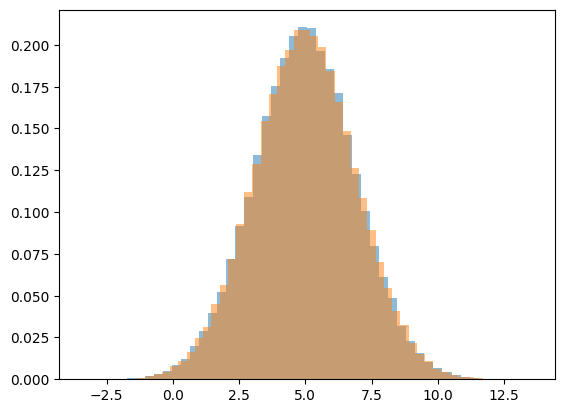

In [7]:
mi = 5
sigma_2 = 3.6

normal_misigma = mi + np.sqrt(sigma_2)*np.array(amostra)

plt.hist(normal_misigma, bins=50, density=True, alpha=.5)
plt.hist(np.random.normal(mi, np.sqrt(sigma_2), n), bins=50, alpha=.5, density=True)
plt.show()

6. Durante a simulação, registre o número total de propostas geradas e calcule a taxa empírica de aceitação,

$$
\widehat{p}_{\text{aceitação}}
=
\frac{\text{número de valores aceitos}}
{\text{número total de propostas}}.
$$

Compare esse valor com a taxa teórica de aceitação do método,

$$
p_{\text{aceitação}}=\frac{1}{c},
$$

onde $c$ é a constante obtida anteriormente. Os valores observado e esperado são compatíveis?

Como visto anteriormente, ficaram muito proximos os valores das probabilidades